In [1]:
from IPython.core.display import display, HTML
import scipy.constants as sc
from scipy.optimize import fsolve
from ipywidgets import interact, widgets
%matplotlib notebook

import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as sc
plt.rcParams.update({
    "text.usetex": True,
    'text.latex.preamble': r"\usepackage{amsmath} \boldmath"
})
import os

print(os.getpid())
%cd ../

22844
/media/work/docs/codes/c++/QSVT_framework/simulations


In [2]:
import XW_waves.xw_1d as xw
mix = xw.mix
mse = xw.mse
reload = mix.reload_module

In [3]:
# choose the case to analyse
case_to_model = "ref"
path_case = "./XW_waves/ref-case"
path_results = "./XW_waves/ref-case/results"

In [7]:
# read .hdf5 files from different restarts:
reload(xw)

dd = {
    "path": path_case,
    "pname": "XW"
}
dd = mse.open_all(dd)
path_fig = path_case + "/" + dd["pname"] + "-" + case_to_model + "-"


--- Reading the file ./XW_waves/ref-case/XW_OUTPUT.hdf5...
Simulation has been performed  08-23-2021 09:53:24

--- Reading the file ./XW_waves/ref-case/XW_1_OUTPUT.hdf5...
Simulation has been performed  08-23-2021 10:50:43

--- Reading the file ./XW_waves/ref-case/XW_2_OUTPUT.hdf5...
Simulation has been performed  08-24-2021 08:50:52

--- Reading the file ./XW_waves/ref-case/XW_3_OUTPUT.hdf5...
Simulation has been performed  08-26-2021 03:06:10


In [8]:
# --- read output states at every time step ---
reload(xw)
mse.read_all_output_states(dd)

# --- read x-grid ---
x_qc = mse.get_x_grid(dd, "j") * 2 - 1
print("size of x-grid is", np.size(x_qc))


--- Reading the file ./XW_waves/ref-case/XW_OUTPUT.hdf5...

--- Reading the file ./XW_waves/ref-case/XW_1_OUTPUT.hdf5...

--- Reading the file ./XW_waves/ref-case/XW_2_OUTPUT.hdf5...

--- Reading the file ./XW_waves/ref-case/XW_3_OUTPUT.hdf5...
size of x-grid is 1024


In [9]:
# --- print initial states ---
reload(xw)

print("-----------------------------------------------------------------------------")
mse.print_initial_states(dd)
print("-----------------------------------------------------------------------------")

-----------------------------------------------------------------------------
--- Initial state ---
Registers: 
{'b': 1, 'q': 1, 'a': 2, 'aj': 2, 'ad': 3, 'd': 3, 'j': 10}

             7.071e-01   |0>|0>|00>|00>|000>|101>|0111001100>
             7.071e-01   |0>|0>|00>|00>|000>|101>|0111001101>
-----------------------------------------------------------------------------


In [14]:
# --- total probability ---
reload(xw)
tot_prob = mse.get_total_prob(dd, -1)
tot_prob

0.9993100779278594

In [10]:
dd["states"][-1]["ampls"]

array([( 4.594e-04,  0.002), (-4.919e-05,  0.   ), ( 2.199e-04,  0.001),
       ..., ( 3.195e-03, -0.002), (-1.775e-01, -0.026),
       (-1.996e-01, -0.04 )], dtype=[('real', '<f8'), ('imag', '<f8')])

In [15]:
# --- Classical simulations: n = 10 ---
reload(xw)
dd_cl = xw.init("ref")
print()
vars_cl = xw.launch(dd_cl)

x_n10 = dd_cl["x-plot"]
t_n10 = dd_cl["t-norm"]

Wv_cl = vars_cl["Wv"]
We_cl = vars_cl["We"]
Wb_cl = vars_cl["Wb"]
Wq_cl = vars_cl["Wq"]
W_n10 = Wv_cl + We_cl + Wb_cl + Wq_cl
Wt_n10 = np.array([np.sum(W_n10[:,i]) for i in range(len(t_n10))])

Simulation of a --- REF --- case

---------------------------------------------------------------------
--- Classical parameters ---
nqx, nx = 10, 1024
t, nt = 325.000, 1300
norm. time step: 2.504e-01
Courant number is: 7.604e-01

---------------------------------------------------------------------
--- QC parameters ---
QC time step: 2.455
QC normalization of a Hamiltonian matrix: 9.804
QC 1/norm_of_H: 1.020e-01
QC source init. value: 7.071e-01
QC time to simulate: 3186.270
QC number of time steps: 1298

Computation... id-t = 1200
Done
(sumx W[1] - sumx W[-1])/sumx W[1]: -8.681e-04


In [18]:
# --- Classical simulations: n = 11 ---
reload(xw)
dd_cl = xw.init("n11")
print()
vars_cl = xw.launch(dd_cl)

x_n11 = dd_cl["x-plot"]
t_n11 = dd_cl["t-norm"]

Wv_cl = vars_cl["Wv"]
We_cl = vars_cl["We"]
Wb_cl = vars_cl["Wb"]
Wq_cl = vars_cl["Wq"]
W_n11 = Wv_cl + We_cl + Wb_cl + Wq_cl
Wt_n11 = np.array([np.sum(W_n11[:,i]) for i in range(len(t_n11))])

Simulation of a --- REF --- case

---------------------------------------------------------------------
--- Classical parameters ---
nqx, nx = 11, 2048
t, nt = 325.000, 2600
norm. time step: 1.251e-01
Courant number is: 7.602e-01

---------------------------------------------------------------------
--- QC parameters ---
QC time step: 2.230
QC normalization of a Hamiltonian matrix: 17.824
QC 1/norm_of_H: 5.610e-02
QC source init. value: 7.071e-01
QC time to simulate: 5792.869
QC number of time steps: 2598

Computation... id-t = 2500
Done
(sumx W[1] - sumx W[-1])/sumx W[1]: -2.784e-04


In [27]:
# --- Classical simulations: n = 12 ---
reload(xw)
dd_cl = xw.init("n12")
print()
vars_cl = xw.launch(dd_cl)

x_n12 = dd_cl["x-plot"]
t_n12 = dd_cl["t-norm"]

Wv_cl = vars_cl["Wv"]
We_cl = vars_cl["We"]
Wb_cl = vars_cl["Wb"]
Wq_cl = vars_cl["Wq"]
W_n12 = Wv_cl + We_cl + Wb_cl + Wq_cl
Wt_n12 = np.array([np.sum(W_n12[:,i]) for i in range(len(t_n12))])

Simulation of a --- REF --- case

---------------------------------------------------------------------
--- Classical parameters ---
nqx, nx = 12, 4096
t, nt = 325.000, 5200
norm. time step: 6.252e-02
Courant number is: 7.601e-01

---------------------------------------------------------------------
--- QC parameters ---
QC time step: 2.170
QC normalization of a Hamiltonian matrix: 34.706
QC 1/norm_of_H: 2.881e-02
QC source init. value: 7.071e-01
QC time to simulate: 11279.481
QC number of time steps: 5198

Computation... id-t = 5100
Done
(sumx W[1] - sumx W[-1])/sumx W[1]: -9.133e-05


<IPython.core.display.Javascript object>


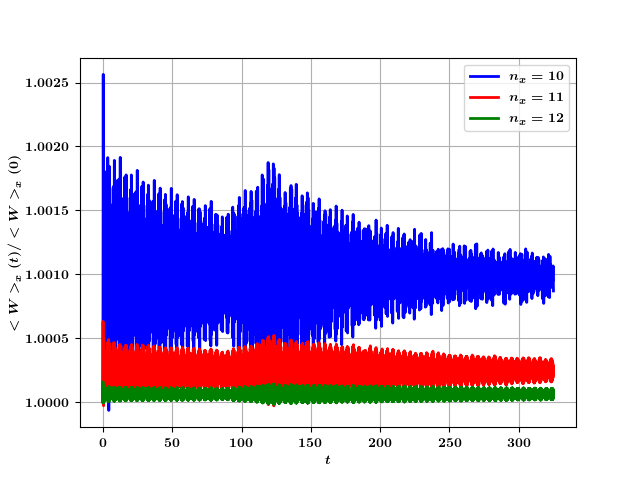

In [28]:
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(
    t_n10, Wt_n10/Wt_n10[0],  
    color='b', 
    linewidth = 2, linestyle='-',
    label = "$n_x = 10$" 
)
ax.plot(
    t_n11, Wt_n11/Wt_n11[0],  
    color='r', 
    linewidth = 2, linestyle='-',
    label = "$n_x = 11$" 
)
ax.plot(
    t_n12, Wt_n12/Wt_n12[0],  
    color='g', 
    linewidth = 2, linestyle='-',
    label = "$n_x = 12$" 
)
plt.xlabel('$t$')
plt.ylabel("$<W>_x(t)/<W>_x(0)$")
ax.legend()
plt.grid(True)
plt.show()
plt.savefig('/media/work/docs/codes/c++/QSVT_framework/simulations/XW_waves/ref-case/figs/W-conv.png')